# 05 - Feature Engineering

## Objective

Build the model features from the raw PaySim data. Every feature must be known **before** the transaction is scored.

Rules we follow:
- `newbalanceOrig`, `newbalanceDest` and `isFlaggedFraud` are not loaded at all (notebook 04).
- `isFraud` is never used to build a feature.
- History features (account behaviour) only use **earlier steps**. Rows of the same step are not used, because PaySim has no order inside a step.

The code is in `src/features/`. This notebook runs it, checks it, and looks at the result.

## Imports and Data Loading

In [20]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('..')
from src.features import config
from src.features.feature_pipeline import build_features, build_model_table, save_table

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [21]:
# Only the columns we are allowed to use. The leaky balance columns are skipped.
use_cols = ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg',
            'nameDest', 'oldbalanceDest', 'isFraud']
dtypes = {'step': 'int32', 'type': 'category', 'amount': 'float64', 'nameOrig': 'string',
          'oldbalanceOrg': 'float64', 'nameDest': 'string', 'oldbalanceDest': 'float64',
          'isFraud': 'int8'}

raw = pd.read_csv(config.RAW_PATH, usecols=use_cols, dtype=dtypes)
raw = raw[use_cols]
print(f'Loaded {len(raw):,} rows, {raw.shape[1]} columns')
print(f'Memory: {raw.memory_usage(deep=True).sum() / 1e6:.0f} MB')

Loaded 6,362,620 rows, 8 columns
Memory: 426 MB


## 1. Is one step really one hour?

PaySim says 1 step = 1 hour. We check that the volume has a 24 hour cycle before building time features.

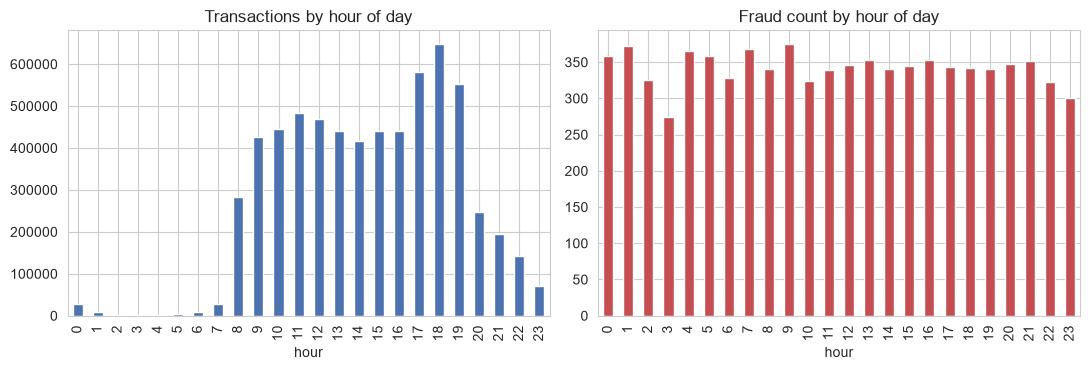

,n,frauds,fraud_rate_pct
hour,,,
0,27111,358,1.3205
1,9018,372,4.1251
2,2007,326,16.2431
3,1241,274,22.0790
4,1641,366,22.3035
5,3420,358,10.4678
6,8988,328,3.6493
7,26915,368,1.3673
8,283518,341,0.1203


In [22]:
tmp = pd.DataFrame({'hour': (raw['step'] - 1) % 24, 'isFraud': raw['isFraud']})
by_hour = tmp.groupby('hour')['isFraud'].agg(n='size', frauds='sum')
by_hour['fraud_rate_pct'] = by_hour['frauds'] / by_hour['n'] * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_hour['n'].plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Transactions by hour of day')
by_hour['frauds'].plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('Fraud count by hour of day')
plt.tight_layout()
plt.savefig('../reports/figures/hour_of_day.png', dpi=120)
plt.show()
by_hour.round(4)

**Observation:** Yes, one step is one hour. The volume has a clear 24 hour cycle. From hour 8 to 19 there are 280k to 650k transactions per hour. From hour 0 to 7 there are only 1k to 27k.

Fraud does not follow this cycle. There are about 340 frauds in every hour, day or night. So the fraud rate is very high at night (16% to 22% at hours 2 to 4) and very low during the day (0.05% to 0.08%).


## 2. Build the features

In [23]:
start = time.time()
feats = build_features(raw)
print(f'Built {feats.shape[1]} features for {len(feats):,} rows in {time.time() - start:.0f} s')
print(f'Feature memory: {feats.memory_usage().sum() / 1e6:.0f} MB')
feats.dtypes.value_counts()

Built 26 features for 6,362,620 rows in 22 s
Feature memory: 426 MB


int8       11
float32     8
int32       5
int16       2
Name: count, dtype: int64

## 3. Leakage checks on the history features

Two tests, both on the real data.

**Test A - slow reference.** For a sample of rows, we recompute the destination history with plain pandas filters (`step` strictly smaller) and compare.

**Test B - cut the future.** We rebuild the features using only rows up to step 300, then compare with the full run on those same rows. If a feature used any future row, the values would change.

In [24]:
# Test A: pick rows whose destination appears several times, plus some random rows
rng = np.random.default_rng(config.RANDOM_SEED)
dest_counts = raw['nameDest'].map(raw['nameDest'].value_counts())
busy = rng.choice(raw.index[dest_counts > 20], size=100, replace=False)
anyrow = rng.choice(raw.index, size=100, replace=False)
sample = np.concatenate([busy, anyrow])

by_dest = raw.groupby('nameDest').indices   # dest -> row positions
errors = 0
for i in sample:
    row = raw.iloc[i]
    block = raw.iloc[by_dest[row['nameDest']]]
    past = block[block['step'] < row['step']]
    recent = past[past['step'] >= row['step'] - config.RECENT_WINDOW]
    ok = (feats['dest_txn_count_before'].iloc[i] == len(past)
          and feats['dest_unique_origins_before'].iloc[i] == past['nameOrig'].nunique()
          and feats['dest_txn_count_recent'].iloc[i] == len(recent)
          and np.isclose(feats['dest_amount_sum_recent'].iloc[i], recent['amount'].sum(), rtol=1e-4))
    errors += (not ok)
print(f'Test A: {len(sample)} rows checked, {errors} mismatches')

Test A: 200 rows checked, 0 mismatches


In [25]:
# Test B: remove everything after step 300 and rebuild
cut = 300
early = raw[raw['step'] <= cut]
early_feats = build_features(early)

same = np.isclose(feats.loc[early.index].to_numpy(dtype='float64'),
                  early_feats.to_numpy(dtype='float64'), rtol=1e-4, atol=1e-4)
bad_cols = feats.columns[~same.all(axis=0)].tolist()
print(f'Test B: rows compared = {len(early):,}')
print('Columns that changed when the future was removed:', bad_cols if bad_cols else 'none')

Test B: rows compared = 4,073,650
Columns that changed when the future was removed: none


**Observation:** Test A found 0 mismatches on 200 rows. In test B, 4,073,650 rows were compared and no column changed after removing everything after step 300. So the history features only use earlier steps.

## 4. Feature quality

In [26]:
quality = pd.DataFrame({
    'dtype': feats.dtypes.astype(str),
    'missing': feats.isna().sum(),
    'infinite': np.isinf(feats.to_numpy(dtype='float64')).sum(axis=0),
    'n_unique': feats.nunique(),
    'top_value_share': feats.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
})
quality['group'] = [config.FEATURES[c][0] for c in quality.index]
quality.round(4)

,dtype,missing,infinite,n_unique,top_value_share,group
amount_log,float32,0,0,3734559,0.0005,transaction
oldbalanceOrg_log,float32,0,0,1652758,0.3304,transaction
oldbalanceDest_log,float32,0,0,2685056,0.4250,transaction
amount_to_balance_ratio,float32,0,0,4181862,0.3304,transaction
zero_old_balance_orig,int8,0,0,2,0.6696,transaction
empties_balance_flag,int8,0,0,2,0.6873,transaction
type_CASH_IN,int8,0,0,2,0.7801,transaction
type_CASH_OUT,int8,0,0,2,0.6483,transaction
type_DEBIT,int8,0,0,2,0.9935,transaction
type_PAYMENT,int8,0,0,2,0.6619,transaction


In [27]:
# Constant or almost constant features
quality[quality['top_value_share'] > 0.99]

,dtype,missing,infinite,n_unique,top_value_share,group
type_DEBIT,int8,0,0,2,0.993488,transaction
orig_txn_count_before,int32,0,0,3,0.998544,origin
orig_is_repeat,int8,0,0,2,0.998544,origin
orig_avg_amount_before,float32,0,0,9263,0.998544,origin
orig_txn_count_recent,int32,0,0,2,0.999826,origin
orig_amount_sum_recent,float32,0,0,1106,0.999826,origin


In [28]:
feats.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
amount_log,6362620.0,10.841,1.815,0.0,9.502,11.224,12.249,1.834200e+01
oldbalanceOrg_log,6362620.0,7.415,5.670,0.0,0.000,9.562,11.584,1.790300e+01
oldbalanceDest_log,6362620.0,7.722,6.748,0.0,0.000,11.796,13.757,1.969000e+01
amount_to_balance_ratio,6362620.0,81.383,3395.713,-1.0,-1.000,0.077,2.219,3.925476e+06
zero_old_balance_orig,6362620.0,0.330,0.470,0.0,0.000,0.000,1.000,1.000000e+00
empties_balance_flag,6362620.0,0.313,0.464,0.0,0.000,0.000,1.000,1.000000e+00
type_CASH_IN,6362620.0,0.220,0.414,0.0,0.000,0.000,0.000,1.000000e+00
type_CASH_OUT,6362620.0,0.352,0.477,0.0,0.000,0.000,1.000,1.000000e+00
type_DEBIT,6362620.0,0.007,0.080,0.0,0.000,0.000,0.000,1.000000e+00
type_PAYMENT,6362620.0,0.338,0.473,0.0,0.000,0.000,1.000,1.000000e+00


**Observation:** No missing values, no infinite values, and the number of rows is the same as the raw data.
- The `orig_*` features are 0 (or -1) in more than 99.8% of the rows.
- 43.5% of the rows have no destination history. Part of it is the start of the simulation, where nobody has a history yet.
- `dest_unique_origins_before` has exactly the same distribution as `dest_txn_count_before`. Almost every sender is unique, so it is the same feature. We keep only the count.

## 5. Do the features separate fraud from non-fraud?

Fraud only happens in `CASH_OUT` and `TRANSFER`, so we compare the two classes **inside these two types only**. Comparing on all types would mix in 3.6M transactions that can never be fraud.

In [29]:
is_fraud_type = raw['type'].isin(config.FRAUD_TYPES).to_numpy()
y = raw['isFraud'].to_numpy()
sub = feats[is_fraud_type].copy()
sub['isFraud'] = y[is_fraud_type]

print('Rows in CASH_OUT / TRANSFER:', len(sub))
print(sub['isFraud'].value_counts().to_string())

numeric_cols = [c for c in feats.columns if not c.startswith('type_')]
medians = sub.groupby('isFraud')[numeric_cols].median().T
means = sub.groupby('isFraud')[numeric_cols].mean().T
compare = medians.join(means, lsuffix='_median', rsuffix='_mean')
compare.columns = ['legit_median', 'fraud_median', 'legit_mean', 'fraud_mean']
compare.round(3)

Rows in CASH_OUT / TRANSFER: 2770409
isFraud
0    2762196
1       8213


,legit_median,fraud_median,legit_mean,fraud_mean
amount_log,12.050,12.998,11.925,12.892
oldbalanceOrg_log,5.649,12.992,5.253,12.865
oldbalanceDest_log,13.233,0.000,11.583,4.479
amount_to_balance_ratio,0.220,1.000,145.499,0.989
zero_old_balance_orig,0.000,0.000,0.474,0.005
empties_balance_flag,0.000,1.000,0.428,0.977
step,236.000,367.000,241.632,368.414
hour_of_day,15.000,11.000,14.476,11.423
day_index,9.000,15.000,9.423,14.833
dest_txn_count_before,5.000,0.000,7.630,2.688


**Observation:** Inside `CASH_OUT` and `TRANSFER`, the two classes are clearly different.
- `amount_to_balance_ratio`: the fraud median is 1.0, the legit median is 0.22. Fraud takes the whole balance.
- `oldbalanceOrg_log`: 12.99 for fraud and 5.65 for legit. Fraud goes after accounts that have money. Only 0.5% of fraud starts from a zero balance, against 47.4% of legit.
- `oldbalanceDest_log`: the fraud median is 0 and the legit median is 13.2. The destination of a fraud is usually empty.
- Destination history: 63.3% of fraud goes to a destination with no earlier transaction, against 15.1% of legit.
- `step` and `day_index`: the fraud median step is 367 against 236 for legit. This comes from the drop of normal volume after step 400, not from a different fraud behaviour. We will not use them.
- `orig_*` features: almost no difference.

### Amount to balance ratio, by type

In [30]:
ratio_tab = (sub[sub['amount_to_balance_ratio'] >= 0]
             .assign(type=raw.loc[sub.index, 'type'].astype(str))
             .groupby(['type', 'isFraud'])['amount_to_balance_ratio']
             .describe()[['count', '25%', '50%', '75%']])
ratio_tab.round(3)

count    25%     50%     75%
type     isFraud                                  
CASH_OUT 0        1207622.0  1.297   4.779  18.089
         1           4079.0  1.000   1.000   1.000
TRANSFER 0         246033.0  4.049  16.226  69.621
         1           4093.0  1.000   1.000   1.000

In [31]:
share_empty = (sub[sub['amount_to_balance_ratio'] >= 0]
               .assign(type=raw.loc[sub.index, 'type'].astype(str))
               .groupby(['type', 'isFraud'])['empties_balance_flag'].mean())
share_empty.round(4)

type      isFraud
CASH_OUT  0          0.7926
          1          0.9998
TRANSFER  0          0.9142
          1          0.9636
Name: empties_balance_flag, dtype: float64

**Observation:** For fraud the ratio is exactly 1.0 in both types (the 25%, 50% and 75% values are all 1.000). The fraudster takes the full balance. Legit transactions are far above 1 (median 4.8 for `CASH_OUT` and 16.2 for `TRANSFER`), because in PaySim the amount is often bigger than the balance.

`empties_balance_flag` (ratio >= 0.99) is weak inside these two types. 79.3% of legit `CASH_OUT` and 91.4% of legit `TRANSFER` also pass it, against 99.98% and 96.4% of fraud. In notebook 03 the gap looked much bigger (98% vs 47%) because all types were mixed. It was mostly a type effect.

### Origin history: is it sparse?

In notebook 02 almost every sender appeared only once. We check how many rows have any history.

In [32]:
orig_cols = config.names_by_group('origin')
print('Share of rows with a previous transaction by the same sender:')
print(f"{feats['orig_is_repeat'].mean() * 100:.3f}%")
print()
print('Same share among fraud rows:')
print(f"{feats.loc[y == 1, 'orig_is_repeat'].mean() * 100:.3f}%")

Share of rows with a previous transaction by the same sender:
0.146%

Same share among fraud rows:
0.219%


**Observation:** Only 0.146% of the rows have an earlier transaction from the same sender (0.219% of the fraud rows). The `orig_*` features are almost always empty, so they are not useful. We drop all five.

### Destination history

In [33]:
tab = sub.copy()
tab['dest_count_bucket'] = pd.cut(tab['dest_txn_count_before'],
                                  [-1, 0, 1, 3, 10, 50, np.inf],
                                  labels=['0', '1', '2-3', '4-10', '11-50', '50+'])
dest_rate = tab.groupby('dest_count_bucket', observed=True)['isFraud'].agg(n='size', frauds='sum')
dest_rate['fraud_rate_pct'] = dest_rate['frauds'] / dest_rate['n'] * 100
dest_rate.round(4)

,n,frauds,fraud_rate_pct
dest_count_bucket,,,
0,422646,5196,1.2294
1,298040,565,0.1896
2-3,453207,722,0.1593
4-10,873093,1043,0.1195
11-50,718765,682,0.0949
50+,4658,5,0.1073


In [34]:
recent_rate = (sub.assign(has_recent=sub['dest_txn_count_recent'] > 0)
               .groupby('has_recent')['isFraud'].agg(n='size', frauds='sum'))
recent_rate['fraud_rate_pct'] = recent_rate['frauds'] / recent_rate['n'] * 100
recent_rate.round(4)

,n,frauds,fraud_rate_pct
has_recent,,,
False,1226189,7182,0.5857
True,1544220,1031,0.0668


**Observation:** Destination history is a strong signal. When the destination has no earlier transaction, the fraud rate is 1.23%. In all the other groups it is between 0.09% and 0.19%, so about 10 times lower. It is the same with recent activity: 0.586% when there was no transaction in the last 24 steps, 0.067% otherwise. Fraud goes to new and quiet accounts.

One warning: at the start of the simulation every destination is new, so `dest_is_new` is true for early rows for a simple reason. This also happens for legit rows, so it is not a big problem, but we must check the models on a later period.

### Plots

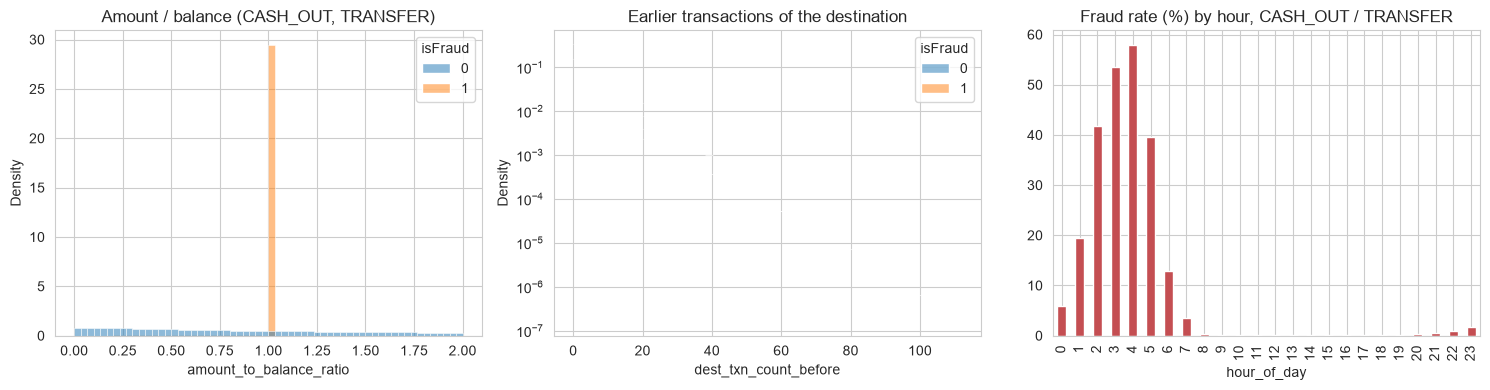

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

clip = sub[(sub['amount_to_balance_ratio'] >= 0) & (sub['amount_to_balance_ratio'] <= 2)]
sns.histplot(data=clip, x='amount_to_balance_ratio', hue='isFraud', bins=60,
             stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Amount / balance (CASH_OUT, TRANSFER)')

sns.histplot(data=sub, x='dest_txn_count_before', hue='isFraud', bins=50,
             stat='density', common_norm=False, ax=axes[1], log_scale=(False, True))
axes[1].set_title('Earlier transactions of the destination')

hour_rate = sub.groupby('hour_of_day')['isFraud'].mean() * 100
hour_rate.plot(kind='bar', ax=axes[2], color='#C44E52')
axes[2].set_title('Fraud rate (%) by hour, CASH_OUT / TRANSFER')

plt.tight_layout()
plt.savefig('../reports/figures/engineered_features.png', dpi=120)
plt.show()

## 6. Feature decisions

Decisions come from `config.FEATURES`. `keep` goes to the first models. `review` is built and saved, but we only keep it if the models show it helps.

In [36]:
registry = pd.DataFrame(
    [(n, g, d, desc) for n, (g, d, desc) in config.FEATURES.items()],
    columns=['feature', 'group', 'decision', 'description'])
registry.sort_values(['decision', 'group'])

,feature,group,decision,description
8,dest_txn_count_before,destination,keep,transactions received by the destination in ea...
9,dest_avg_amount_before,destination,keep,average amount received in earlier steps (-1 i...
10,dest_unique_origins_before,destination,keep,distinct senders seen in earlier steps
11,dest_is_new,destination,keep,destination has no earlier transaction
12,dest_txn_count_recent,destination,keep,transactions received in the last 24 steps
13,dest_amount_sum_recent,destination,keep,amount received in the last 24 steps
6,hour_of_day,time,keep,(step - 1) % 24
25,step,time,keep,raw simulation hour
0,amount_log,transaction,keep,log1p(amount)
1,oldbalanceOrg_log,transaction,keep,log1p(oldbalanceOrg)


In [37]:
pd.DataFrame(list(config.DROPPED.items()), columns=['not built / dropped', 'reason'])

,not built / dropped,reason
0,newbalanceOrig / newbalanceDest and anything b...,confirmed leakage (notebook 04)
1,isFlaggedFraud,catches 0.19% of fraud
2,dest_type (merchant / customer),same information as type == PAYMENT
3,period_early_late,"mostly a volume artifact, risky for a temporal..."
4,nameOrig / nameDest as categories,"too many unique values, used only as group keys"


## 7. Save the table

In [38]:
table = build_model_table(raw)
path = save_table(table)
print(f'Saved {table.shape} to {path}')
print(f'File size: {os.path.getsize(path) / 1e6:.0f} MB')
print(f'Fraud rows kept: {table["isFraud"].sum():,}')
assert len(table) == len(raw)

Saved (6362620, 28) to ..\data\processed\features_v1.parquet
File size: 180 MB
Fraud rows kept: 8,213


## 8. Conclusion and next step

We built 26 features for 6,362,620 rows. The row count did not change, there are no missing or infinite values, and both leakage tests passed. The table has 28 columns and is saved as a 180 MB parquet file.

**Decisions**
- **Keep:** `amount_log`, `oldbalanceOrg_log`, `oldbalanceDest_log`, `amount_to_balance_ratio`, `zero_old_balance_orig`, `type_TRANSFER`, `dest_txn_count_before`, `dest_avg_amount_before`, `dest_is_new`, `dest_txn_count_recent`, `dest_amount_sum_recent`.
- **Add (notebook 06):** `ratio_gap_to_one` and `ratio_is_one`, because fraud has a ratio of exactly 1.
- **Review:** `hour_of_day` and `dest_steps_since_last`.
- **Drop:** the 5 `orig_*` features (no history for 99.85% of senders), `dest_unique_origins_before` (same as the count), `empties_balance_flag`, `step` and `day_index` (volume effect).

Fraud only exists in `CASH_OUT` and `TRANSFER` (0 fraud in the other 3.59M rows), so the models will be trained only on these two types.

The history features use only earlier steps, so they can be used with a time-based split.

Next notebook: `06_baseline_models.ipynb` (validation strategy and baselines).